# 02 – Preprocessing & Feature Engineering

**Đầu vào:** `data/WA_Fn-UseC_-Telco-Customer-Churn.csv` (dữ liệu gốc)
**Đầu ra:**
- `data/processed/telco_clean.csv`: dữ liệu đã làm sạch, có đủ cột gốc và cột mới. **Chưa scale, chưa encode.**
- `data/processed/splits.csv`: bảng `customerID → train / val / test`.

Toàn bộ logic nằm trong [`src/preprocessing.py`](../src/preprocessing.py), tham số trong [`src/config.yaml`](../src/config.yaml). Notebook này chỉ **chạy từng bước và kiểm tra kết quả**.

| Làm trong notebook này | Để dành cho bước mô hình |
|---|---|
| 1. Làm sạch dữ liệu | Xử lý mất cân bằng lớp |
| 2. Feature engineering | Chọn feature (bộ cột cho LR / mô hình cây) |
| 3. Chia train / val / test | Calibration |
| 4. Kiểm tra tuyến tính với log-odds (trên train) | |
| 5. Định nghĩa encoding & scaling (`build_preprocessor`) | |

## 0. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import statsmodels.api as sm
from IPython.display import display

from src import preprocessing as pp

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

config = pp.load_config()
config

{'random_state': 42,
 'paths': {'raw_data': 'data/WA_Fn-UseC_-Telco-Customer-Churn.csv',
  'clean_data': 'data/processed/telco_clean.csv',
  'splits': 'data/processed/splits.csv'},
 'split': {'test_size': 0.2, 'val_size': 0.2, 'stratify': True},
 'features': {'new_customer_max_tenure': 12,
  'monthly_charge_bins': [0, 25, 70, 100, inf],
  'monthly_charge_labels': ['<=25', '25-70', '70-100', '>100']}}

In [2]:
# Style biểu đồ đồng nhất với notebook 01
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 10,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
FIG_DIR = ROOT / "eda_output" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Làm sạch dữ liệu – `clean_data()`

| # | Việc | Cách làm | Lý do (EDA mục 8.2) |
|---|---|---|---|
| 1 | `TotalCharges` | Ép sang số; 11 chuỗi rỗng → **0** | Cả 11 dòng đều là khách `tenure = 0`, chưa có hoá đơn. Hàm **báo lỗi** nếu gặp giá trị thiếu ở khách có tenure > 0 |
| 2 | `"No internet service"` / `"No phone service"` | Gộp về `"No"` | Trùng 100% với `InternetService = No` / `PhoneService = No` |
| 3 | 11 cột Yes/No | Đổi thành 1/0 | Đồng nhất với `SeniorCitizen`. Hàm báo lỗi nếu gặp giá trị lạ |
| 4 | `Churn` | Đổi thành cột `y` dạng 0/1, bỏ cột `Churn` | Nhãn |
| 5 | `customerID` | Giữ làm khoá | Dùng để ghép với bảng targeting |
| 6 | 22 dòng trùng đặc trưng, ngoại lai | Không xử lý | Không phải lỗi, theo IQR không có ngoại lai |

In [3]:
raw = pp.load_raw(config)
clean = pp.clean_data(raw)
print("raw  :", raw.shape)
print("clean:", clean.shape)

raw  : (7043, 21)
clean: (7043, 21)


### 1.1 Kiểm tra

In [4]:
changed = [c for c in raw.columns if c in clean.columns and raw[c].dtype != clean[c].dtype]
display(pd.DataFrame({"dtype trước": raw[changed].dtypes.astype(str), "dtype sau": clean[changed].dtypes.astype(str)}))

blank_tc = raw["TotalCharges"].str.strip().eq("")
display(pd.DataFrame({
    "customerID": raw.loc[blank_tc, "customerID"],
    "tenure": raw.loc[blank_tc, "tenure"],
    "TotalCharges (raw)": raw.loc[blank_tc, "TotalCharges"].map(repr),
    "TotalCharges (clean)": clean.loc[blank_tc, "TotalCharges"],
}).head(11))

,dtype trước,dtype sau
Partner,object,int64
Dependents,object,int64
PhoneService,object,int64
MultipleLines,object,int64
OnlineSecurity,object,int64
OnlineBackup,object,int64
DeviceProtection,object,int64
TechSupport,object,int64
StreamingTV,object,int64
StreamingMovies,object,int64


,customerID,tenure,TotalCharges (raw),TotalCharges (clean)
488,4472-LVYGI,0,' ',0.0
753,3115-CZMZD,0,' ',0.0
936,5709-LVOEQ,0,' ',0.0
1082,4367-NUYAO,0,' ',0.0
1340,1371-DWPAZ,0,' ',0.0
3331,7644-OMVMY,0,' ',0.0
3826,3213-VVOLG,0,' ',0.0
4380,2520-SGTTA,0,' ',0.0
5218,2923-ARZLG,0,' ',0.0
6670,4075-WKNIU,0,' ',0.0


In [5]:
for c in ["OnlineSecurity", "MultipleLines"]:
    print(f"{c:<15} trước: {raw[c].value_counts().to_dict()}")
    print(f"{'':<15} sau  : {clean[c].value_counts().to_dict()}")

OnlineSecurity  trước: {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
                sau  : {0: 5024, 1: 2019}
MultipleLines   trước: {'No': 3390, 'Yes': 2971, 'No phone service': 682}
                sau  : {0: 4072, 1: 2971}


In [6]:
checks = {
    "Số dòng giữ nguyên (7,043)": len(clean) == len(raw) == 7043,
    "Không còn NaN": clean.isna().sum().sum() == 0,
    "TotalCharges là số": pd.api.types.is_numeric_dtype(clean["TotalCharges"]),
    "Không còn nhãn 'No ... service'": not clean.isin(["No internet service", "No phone service"]).any().any(),
    "Cột Yes/No chỉ chứa 0/1": clean[pp.YES_NO_COLS].isin([0, 1]).all().all(),
    "Tỉ lệ churn không đổi": np.isclose(clean[pp.TARGET].mean(), raw["Churn"].eq("Yes").mean()),
    "customerID không trùng": clean[pp.ID_COL].is_unique,
}
display(pd.Series(checks, name="Đạt").to_frame())
assert all(checks.values())

,Đạt
"Số dòng giữ nguyên (7,043)",True
Không còn NaN,True
TotalCharges là số,True
Không còn nhãn 'No ... service',True
Cột Yes/No chỉ chứa 0/1,True
Tỉ lệ churn không đổi,True
customerID không trùng,True


## 2. Feature engineering – `add_features()`

Tạo **tất cả biến ứng viên** có lý do từ EDA. Việc chọn dùng biến nào để dành cho bước mô hình.

| Nhóm | Biến | Định nghĩa | Lý do từ EDA |
|---|---|---|---|
| Vòng đời | `is_new_customer` | `tenure ≤ 12` | Giai đoạn rủi ro nhất. **Cờ nghiệp vụ** cho phân khúc và playbook ("khách năm đầu"), không dùng chung với `tenure` trong LR (xem mục 4.1) |
| Dịch vụ | `num_addons` | Số dịch vụ bổ sung internet đang dùng (0–6) | Càng dùng nhiều dịch vụ càng gắn bó |
| | `has_protection` | Có `OnlineSecurity` hoặc `TechSupport` | Hai driver mạnh nhất trong nhóm dịch vụ |
| | `has_streaming` | Có `StreamingTV` hoặc `StreamingMovies` | Gộp hai biến có cùng hành vi |
| Thanh toán | `auto_payment` | Bank transfer / Credit card (automatic) | Electronic check churn 45%, thanh toán tự động khoảng 15–17% |
| Cước | `monthly_charge_band` | `MonthlyCharges` chia 4 khoảng: ≤25 / 25-70 / 70-100 / >100 | EDA 7.1 (f16): churn tăng theo cước đến khoảng $100 rồi **giảm lại** ở decile cao nhất. Quan hệ không đơn điệu |
| | `log_TotalCharges` | `log(1 + TotalCharges)` | EDA 4.2 / 5.2: lệch phải (skew 0.96), churn dồn ở vùng thấp. EDA 8.2 #5 đã gợi ý log-transform |
| | `avg_past_charge` | `TotalCharges / tenure`; khách tenure 0 lấy bằng `MonthlyCharges` | Mức cước trung bình trong quá khứ |
| | `charge_change` | `MonthlyCharges − avg_past_charge` | Cước tăng hay giảm. Là phương án thay `TotalCharges` nếu cần bỏ cột này vì đa cộng tuyến |
| Tương tác | `m2m_fiber` | Month-to-month **và** Fiber optic | Tổ hợp này churn 55% |
| | `m2m_echeck` | Month-to-month **và** Electronic check | Tổ hợp này churn 54% |

Các ngưỡng (`new_customer_max_tenure`, `monthly_charge_bins`) đọc từ `config.yaml`. Ngưỡng 25 / 70 / 100 của `monthly_charge_band` được làm tròn từ các mốc decile trong EDA (25.05 / 70.35 / 102.6).

`tenure` **giữ dạng số, không chia khoảng.** Phiên bản trước có biến `tenure_group` (5 khoảng), nhưng đã bỏ vì kiểm tra ở mục 4.1 cho thấy biến này kém hơn `tenure` dạng số.

In [7]:
df = pp.add_features(clean, config)
print("Sau feature engineering:", df.shape)
df[[pp.ID_COL, "tenure", "MonthlyCharges", "TotalCharges", *pp.ENGINEERED_COLS]].head()

Sau feature engineering: (7043, 32)


,customerID,tenure,MonthlyCharges,TotalCharges,is_new_customer,num_addons,has_protection,has_streaming,auto_payment,monthly_charge_band,log_TotalCharges,avg_past_charge,charge_change,m2m_fiber,m2m_echeck
0,7590-VHVEG,1,29.85,29.85,1,1,0,0,0,25-70,3.429137,29.850000,0.000000,0,1
1,5575-GNVDE,34,56.95,1889.50,0,2,1,0,0,25-70,7.544597,55.573529,1.376471,0,0
2,3668-QPYBK,2,53.85,108.15,1,2,1,0,0,25-70,4.692723,54.075000,-0.225000,0,0
3,7795-CFOCW,45,42.30,1840.75,0,3,1,0,1,25-70,7.518471,40.905556,1.394444,0,0
4,9237-HQITU,2,70.70,151.65,1,0,0,0,0,70-100,5.028148,75.825000,-5.125000,1,1


### 2.1 Kiểm tra tính đúng

In [8]:
num = df.select_dtypes("number")
tenure0 = df["tenure"].eq(0)
checks = {
    "Không có NaN": df.isna().sum().sum() == 0,
    "Không có inf": not np.isinf(num).any().any(),
    "tenure = 0 → avg_past_charge = MonthlyCharges": np.allclose(df.loc[tenure0, "avg_past_charge"], df.loc[tenure0, "MonthlyCharges"]),
    "num_addons trong [0, 6]": df["num_addons"].between(0, 6).all(),
    "Khách không có internet → num_addons = 0": df.loc[df["InternetService"].eq("No"), "num_addons"].eq(0).all(),
    "monthly_charge_band không có giá trị 'nan'": not df["monthly_charge_band"].eq("nan").any(),
    "tenure = 0 → log_TotalCharges = 0": df.loc[tenure0, "log_TotalCharges"].eq(0).all(),
    "m2m_fiber khớp EDA (2,128 khách)": df["m2m_fiber"].sum() == 2128,
    "m2m_echeck khớp EDA (1,850 khách)": df["m2m_echeck"].sum() == 1850,
}
display(pd.Series(checks, name="Đạt").to_frame())
assert all(checks.values())

display(df.groupby("monthly_charge_band", observed=True)["MonthlyCharges"].agg(["min", "max", "size"])
        .loc[config["features"]["monthly_charge_labels"]])

,Đạt
Không có NaN,True
Không có inf,True
tenure = 0 → avg_past_charge = MonthlyCharges,True
"num_addons trong [0, 6]",True
Khách không có internet → num_addons = 0,True
monthly_charge_band không có giá trị 'nan',True
tenure = 0 → log_TotalCharges = 0,True
"m2m_fiber khớp EDA (2,128 khách)",True
"m2m_echeck khớp EDA (1,850 khách)",True


,min,max,size
monthly_charge_band,,,
<=25,18.25,25.00,1406
25-70,25.05,70.00,2054
70-100,70.05,100.00,2681
>100,100.05,118.75,902


### 2.2 Biến mới có tín hiệu với churn không?
Kiểm tra nhanh để xác nhận biến mới có tín hiệu đúng như EDA dự đoán. Đây **không** phải bước chọn feature.

In [9]:
BASE_RATE = df[pp.TARGET].mean()
flag_cols = ["is_new_customer", "has_protection", "has_streaming", "auto_payment", "m2m_fiber", "m2m_echeck"]

flag_signal = pd.concat({
    c: df.groupby(c)[pp.TARGET].agg(n="size", churn_rate="mean") for c in flag_cols
}, names=["Biến", "Giá trị"])
flag_signal["lift"] = flag_signal["churn_rate"] / BASE_RATE
display(flag_signal.style.format({"n": "{:,}", "churn_rate": "{:.1%}", "lift": "{:.2f}×"}))

for c, order in [("num_addons", None), ("monthly_charge_band", config["features"]["monthly_charge_labels"])]:
    t = df.groupby(c)[pp.TARGET].agg(n="size", churn_rate="mean")
    t = t.loc[order] if order else t
    display(t.T.style.format("{:.1%}", subset=pd.IndexSlice["churn_rate", :])
            .format("{:,.0f}", subset=pd.IndexSlice["n", :]).set_caption(c))
display(df.groupby(pp.TARGET)[["avg_past_charge", "charge_change"]].describe().T.round(2))

num_addons,0,1,2,3,4,5,6
n,"2,219",966,"1,033","1,118",852,571,284
churn_rate,21.4%,45.8%,35.8%,27.4%,22.3%,12.4%,5.3%


monthly_charge_band,<=25,25-70,70-100,>100
n,"1,406","2,054","2,681",902
churn_rate,9.0%,23.1%,37.8%,28.0%


y                            0        1
avg_past_charge count  5174.00  1869.00
                mean     61.27    74.43
                std      31.14    24.96
                min      13.78    14.15
                25%      25.35    57.98
                50%      63.98    79.31
                75%      87.72    93.93
                max     120.75   121.40
charge_change   count  5174.00  1869.00
                mean     -0.00     0.01
                std       2.30     3.33
                min     -17.12   -18.90
                25%      -1.12    -1.34
                50%       0.00     0.00
                75%       1.11     1.45
                max      17.02    19.13

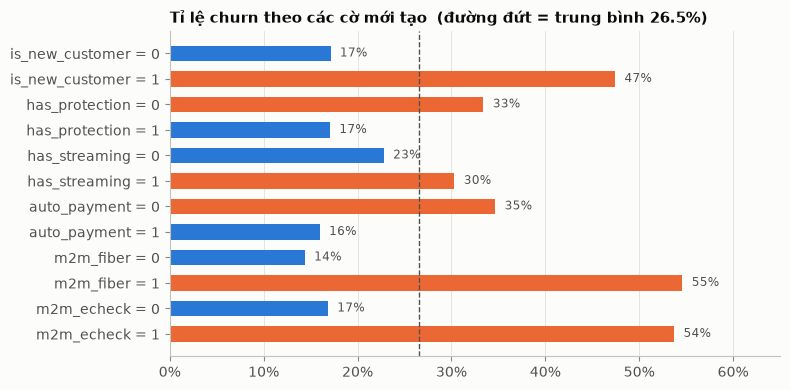

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
rows = [(f"{c} = {v}", r) for c in flag_cols for v, r in df.groupby(c)[pp.TARGET].mean().items()]
labels, rates = zip(*rows[::-1])
colors = [ORANGE if r > BASE_RATE else BLUE for r in rates]
ax.barh(labels, rates, color=colors, height=0.6)
ax.axvline(BASE_RATE, color=INK_2, ls="--", lw=1)
for i, r in enumerate(rates):
    ax.text(r + 0.01, i, f"{r:.0%}", va="center", fontsize=8.5, color=INK_2)
ax.set_xlim(0, 0.65)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
ax.set_title(f"Tỉ lệ churn theo các cờ mới tạo  (đường đứt = trung bình {BASE_RATE:.1%})", loc="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "p01_engineered_flags.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.3 Cặp biến tương quan cao (ghi chú cho bước chọn feature)
Liệt kê các cặp có |r| > 0.7 giữa biến số và biến nhị phân. Bước này chỉ **ghi lại**, không loại cột nào.

In [11]:
corr = df[pp.NUM_COLS + pp.BIN_COLS].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
high_corr = upper.stack().loc[lambda s: s > 0.7].sort_values(ascending=False).rename("|r|").round(3)
high_corr.to_frame()

|r|
MonthlyCharges   avg_past_charge   0.996
tenure           log_TotalCharges  0.829
                 TotalCharges      0.826
TotalCharges     log_TotalCharges  0.826
StreamingMovies  has_streaming     0.801
log_TotalCharges is_new_customer   0.797
StreamingTV      has_streaming     0.795
tenure           is_new_customer   0.755
TechSupport      has_protection    0.750
TotalCharges     num_addons        0.745
OnlineSecurity   has_protection    0.744
num_addons       has_streaming     0.738
MonthlyCharges   num_addons        0.725
avg_past_charge  num_addons        0.723
MonthlyCharges   has_streaming     0.703

## 3. Chia train / val / test – `assign_splits()`

- Tỉ lệ 60 / 20 / 20, **stratified theo `y`**, `random_state = 42` (đọc từ config).
- Stratify chỉ để giữ tỉ lệ churn giống nhau giữa các tập, **không phải** xử lý mất cân bằng.
- Chia 2 lần: tách test 20% trước, sau đó tách val (20% của toàn bộ dữ liệu) từ phần còn lại.

| Tập | Dùng cho (ở các bước sau) |
|---|---|
| train | Fit preprocessor và mô hình, cross-validation |
| val | Calibration, chọn ngưỡng, chạy thử simulator |
| test | Chỉ dùng **một lần** để báo cáo kết quả cuối |

In [12]:
splits = pp.assign_splits(df, config)
m = df.merge(splits, on=pp.ID_COL, validate="one_to_one")

summary = m.groupby("split").agg(n=(pp.TARGET, "size"), churn=(pp.TARGET, "sum"), churn_rate=(pp.TARGET, "mean"))
summary["share"] = summary["n"] / len(m)
summary = summary.loc[["train", "val", "test"]]
display(summary.style.format({"n": "{:,}", "churn": "{:,}", "churn_rate": "{:.2%}", "share": "{:.1%}"}))

ids = {k: set(v) for k, v in splits.groupby("split")[pp.ID_COL]}
checks = {
    "Mỗi khách thuộc đúng 1 tập": splits[pp.ID_COL].is_unique and len(splits) == len(df),
    "Không có khách trùng giữa các tập": not (ids["train"] & ids["val"] or ids["train"] & ids["test"] or ids["val"] & ids["test"]),
    "Chênh lệch churn rate giữa các tập < 0.5 điểm %": summary["churn_rate"].max() - summary["churn_rate"].min() < 0.005,
}
display(pd.Series(checks, name="Đạt").to_frame())
assert all(checks.values())

,n,churn,churn_rate,share
split,,,,
train,"4,225","1,121",26.53%,60.0%
val,"1,409",374,26.54%,20.0%
test,"1,409",374,26.54%,20.0%


,Đạt
Mỗi khách thuộc đúng 1 tập,True
Không có khách trùng giữa các tập,True
Chênh lệch churn rate giữa các tập < 0.5 điểm %,True


### 3.1 Lưu kết quả và kiểm tra đọc lại

In [13]:
pp.save_processed(df, splits, config)
reloaded = pp.load_processed(config)

pd.testing.assert_frame_equal(
    reloaded.drop(columns="split").sort_values(pp.ID_COL).reset_index(drop=True),
    df.sort_values(pp.ID_COL).reset_index(drop=True),
    check_dtype=False,
)
print("Đã lưu và đọc lại khớp:")
for key in ["clean_data", "splits"]:
    p = ROOT / config["paths"][key]
    print(f"  {p.relative_to(ROOT)}  ({p.stat().st_size / 1024:,.0f} KB)")
print("Shape khi đọc lại (kèm cột split):", reloaded.shape)

Đã lưu và đọc lại khớp:
  data\processed\telco_clean.csv  (1,162 KB)
  data\processed\splits.csv  (120 KB)
Shape khi đọc lại (kèm cột split): (7043, 33)


## 4. Kiểm tra tuyến tính với log-odds (trên train)

Logistic regression giả định mỗi biến số có quan hệ **tuyến tính với log-odds** của churn. Tương quan Pearson với nhãn 0/1 không kiểm tra được giả định này. Mô hình cây không cần giả định này, nên mục này chủ yếu phục vụ LR.

EDA đã có dấu hiệu phi tuyến cho từng biến:

| Biến | Dấu hiệu trong EDA |
|---|---|
| `tenure` | 6.3 (f13): churn giảm không đều, 52.9% → 35.9% → 28.7% → 20.4% → 9.5% |
| `MonthlyCharges` | 7.1 (f16): churn tăng đến decile 9 (khoảng $98, 41%) rồi giảm còn 25% ở decile 10 |
| `TotalCharges` | 4.2 / 5.2: lệch phải, khách churn dồn ở vùng thấp |
| `num_addons` | 5.1: nhóm không có internet churn 7.4%, nằm lẫn trong nhóm `num_addons = 0` |

Mục này kiểm tra lại bằng 3 cách, **chỉ trên tập train** để không nhìn vào val/test:
- **Empirical logit:** log-odds thực tế của từng decile, so với đường thẳng mà LR một biến khớp được.
- **So sánh AIC:** dạng tuyến tính so với dạng 10 decile (đường cong tự do). Decile thấp hơn **hơn 10 điểm** AIC nghĩa là dạng tuyến tính bỏ sót tín hiệu.
- **Kiểm định Box-Tidwell:** thêm thành phần `x·ln(x)`. p < 0.05 nghĩa là quan hệ không tuyến tính. Với n = 4,225, kiểm định này rất nhạy, nên cần đọc kèm ΔAIC và biểu đồ.

In [14]:
train_df = m[m["split"] == "train"]
y_tr = train_df[pp.TARGET]
LIN_COLS = ["tenure", "MonthlyCharges", "TotalCharges", "avg_past_charge", "charge_change", "num_addons"]


def logit_aic(X):
    return sm.Logit(y_tr, sm.add_constant(X.astype(float))).fit(disp=0).aic


def flexible_groups(x):
    """Decile cho biến liên tục; giữ nguyên giá trị cho biến rời rạc ít mức (num_addons)."""
    return x if x.nunique() <= 10 else pd.qcut(x, 10, duplicates="drop")


def box_tidwell_p(x):
    xs = x - x.min() + 1          # Box-Tidwell cần x > 0
    X = pd.DataFrame({"x": xs, "x_ln_x": xs * np.log(xs)})
    return sm.Logit(y_tr, sm.add_constant(X)).fit(disp=0).pvalues["x_ln_x"]


lin = pd.DataFrame([{
    "Biến": c,
    "AIC tuyến tính": logit_aic(train_df[[c]]),
    "AIC 10 decile": logit_aic(pd.get_dummies(flexible_groups(train_df[c]), drop_first=True)),
    "Box-Tidwell p": box_tidwell_p(train_df[c]),
} for c in LIN_COLS]).set_index("Biến")
lin["ΔAIC (decile − tuyến tính)"] = lin["AIC 10 decile"] - lin["AIC tuyến tính"]
lin["Tuyến tính với log-odds?"] = np.where((lin["Box-Tidwell p"] < 0.05) & (lin["ΔAIC (decile − tuyến tính)"] < -10),
                                           "Không", "Chấp nhận được")
lin.style.format({"AIC tuyến tính": "{:,.0f}", "AIC 10 decile": "{:,.0f}", "Box-Tidwell p": "{:.1e}",
                  "ΔAIC (decile − tuyến tính)": "{:+,.0f}"})

,AIC tuyến tính,AIC 10 decile,Box-Tidwell p,ΔAIC (decile − tuyến tính),Tuyến tính với log-odds?
Biến,,,,,
tenure,"4,315","4,291",5.7e-04,-24,Không
MonthlyCharges,"4,726","4,618",2.1e-15,-108,Không
TotalCharges,"4,702","4,641",5.5e-08,-61,Không
avg_past_charge,"4,727","4,639",9.4e-15,-88,Không
charge_change,"4,893","4,665",4.0e-10,-228,Không
num_addons,"4,859","4,651",1.5e-38,-208,Không


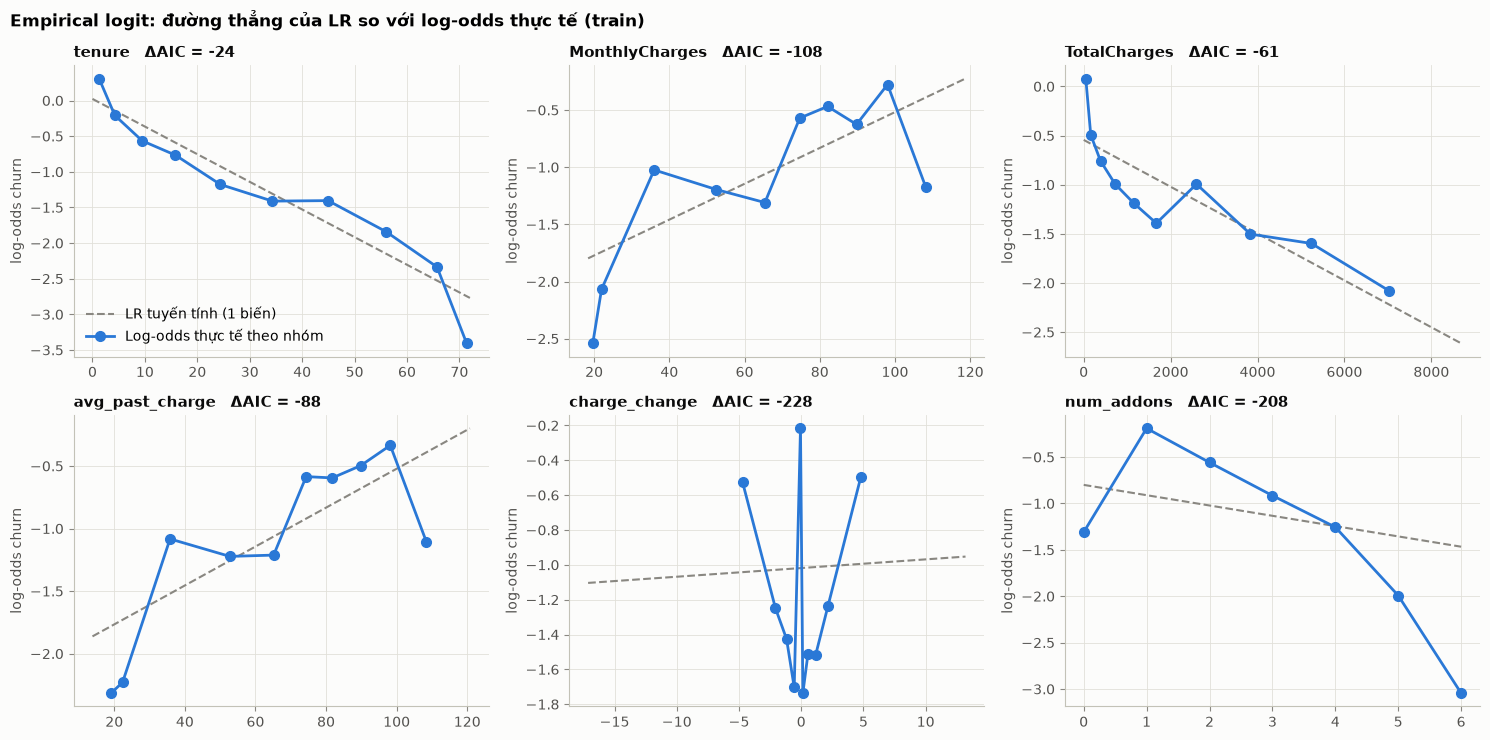

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, c in zip(axes.flat, LIN_COLS):
    x = train_df[c]
    g = train_df.groupby(flexible_groups(x), observed=True).agg(x=(c, "mean"), p=(pp.TARGET, "mean"))
    g["logit"] = np.log(g["p"] / (1 - g["p"]))
    fit = sm.Logit(y_tr, sm.add_constant(x.astype(float))).fit(disp=0)
    xx = np.linspace(x.min(), x.max(), 100)
    ax.plot(xx, fit.params["const"] + fit.params[c] * xx, color=MUTED, ls="--", lw=1.5, label="LR tuyến tính (1 biến)")
    ax.plot(g["x"], g["logit"], color=BLUE, lw=2, marker="o", ms=7, label="Log-odds thực tế theo nhóm")
    d_aic = lin.loc[c, "ΔAIC (decile − tuyến tính)"]
    ax.set_title(f"{c}   ΔAIC = {d_aic:+,.0f}", loc="left")
    ax.set_ylabel("log-odds churn")
axes[0, 0].legend(loc="lower left")
fig.suptitle("Empirical logit: đường thẳng của LR so với log-odds thực tế (train)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "p02_linearity_logit.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.1 Biến đổi từ EDA có khắc phục được không?
So sánh AIC (trên train) của dạng gốc, dạng đã biến đổi (tạo ở mục 2) và dạng 10 decile (mức tham chiếu linh hoạt nhất).

Riêng `tenure`, bảng còn kiểm tra:
- `tenure_group` (5 khoảng 0-6 / 7-12 / 13-24 / 25-48 / 49-72 theo EDA mục 6.3). Biến này được tạo tạm ngay tại đây, vì **đã bị bỏ khỏi preprocessing** dựa trên chính kết quả này.
- Dạng **dùng kèm** `tenure`, để biết `tenure_group` / `is_new_customer` có bổ sung thông tin gì so với `tenure` hay không.

In [16]:
def dummies(s):
    return pd.get_dummies(s, drop_first=True)


tenure_group = pd.cut(train_df["tenure"], [0, 6, 12, 24, 48, 72], include_lowest=True)   # chỉ để so sánh

compare = pd.DataFrame([
    ("tenure", "tuyến tính", logit_aic(train_df[["tenure"]])),
    ("tenure", "tenure_group (5 nhóm), thay cho tenure", logit_aic(dummies(tenure_group))),
    ("tenure", "tenure + tenure_group", logit_aic(pd.concat([train_df[["tenure"]], dummies(tenure_group)], axis=1))),
    ("tenure", "tenure + is_new_customer", logit_aic(train_df[["tenure", "is_new_customer"]])),
    ("MonthlyCharges", "tuyến tính", logit_aic(train_df[["MonthlyCharges"]])),
    ("MonthlyCharges", "monthly_charge_band (4 nhóm)", logit_aic(dummies(train_df["monthly_charge_band"]))),
    ("TotalCharges", "tuyến tính", logit_aic(train_df[["TotalCharges"]])),
    ("TotalCharges", "log_TotalCharges", logit_aic(train_df[["log_TotalCharges"]])),
], columns=["Biến gốc", "Dạng", "AIC"])
compare["AIC 10 decile (tham chiếu)"] = compare["Biến gốc"].map(lin["AIC 10 decile"])
compare["Cải thiện so với tuyến tính"] = compare["AIC"] - compare.groupby("Biến gốc")["AIC"].transform("first")
compare.style.format({"AIC": "{:,.0f}", "AIC 10 decile (tham chiếu)": "{:,.0f}", "Cải thiện so với tuyến tính": "{:+,.0f}"})

,Biến gốc,Dạng,AIC,AIC 10 decile (tham chiếu),Cải thiện so với tuyến tính
0,tenure,tuyến tính,"4,315","4,291",+0
1,tenure,"tenure_group (5 nhóm), thay cho tenure","4,343","4,291",+28
2,tenure,tenure + tenure_group,"4,301","4,291",-14
3,tenure,tenure + is_new_customer,"4,314","4,291",-1
4,MonthlyCharges,tuyến tính,"4,726","4,618",+0
5,MonthlyCharges,monthly_charge_band (4 nhóm),"4,619","4,618",-106
6,TotalCharges,tuyến tính,"4,702","4,641",+0
7,TotalCharges,log_TotalCharges,"4,668","4,641",-33


### 4.2 Kết luận

**Cả 6 biến số đều không tuyến tính với log-odds** (Box-Tidwell p < 0.05 và ΔAIC < −10). Mức độ khác nhau giữa các biến, và các biến đổi rút ra từ EDA khắc phục được một phần:

| Biến | Hình dạng log-odds (biểu đồ p02) | Biến đổi từ EDA | Kết quả |
|---|---|---|---|
| `MonthlyCharges` | Tăng đến khoảng $98 rồi **giảm mạnh** ở decile cao nhất (ΔAIC −108) | `monthly_charge_band` | ✅ **Khắc phục gần hoàn toàn**: AIC 4,619, bằng mức của 10 decile (4,618), chỉ với 4 nhóm |
| `TotalCharges` | Giảm nhanh ở vùng thấp rồi chậm dần (ΔAIC −61) | `log_TotalCharges` | ⚠️ **Khắc phục một phần**: AIC từ 4,702 xuống 4,668, còn cách mức decile 4,641 |
| `tenure` | **Gần thẳng trên thang log-odds**, chỉ dốc mạnh ở đoạn cuối 65–72 tháng (ΔAIC −24, nhỏ nhất) | `tenure_group` | ❌ **Đã bỏ**: thay cho `tenure` thì kém hơn (4,343 so với 4,315); dùng kèm chỉ cải thiện −14 với 4 cột dummy thêm |
| `avg_past_charge` | Giống `MonthlyCharges` (r = 0.996) | Không có (dư thừa) | Dùng `monthly_charge_band` thay |
| `charge_change` | **Hình chữ V** quanh 0 (ΔAIC −228). Điểm nhô tại 0 là 387 khách trên train có `charge_change = 0` (379 khách tenure = 1, 7 khách tenure = 0, vì khi đó `TotalCharges = MonthlyCharges`), churn 62% | Không có trong EDA | Ghi chú cho bước mô hình |
| `num_addons` | Đỉnh tại 1 rồi giảm dần. Nhóm 0 lẫn khách không dùng internet (ΔAIC −208) | Không có trong EDA | Ghi chú cho bước mô hình |

**Về `tenure`:** đường churn rate trong EDA (mục 6.3) trông phi tuyến, nhưng đó là trên **thang xác suất**. Trên **thang log-odds**, thang mà LR thực sự làm việc, `tenure` gần như thẳng. Do đó:
- **Bỏ `tenure_group`** khỏi preprocessing. Thay cho `tenure` thì kém hơn, dùng kèm thì cải thiện quá nhỏ. Mô hình cây tự tìm ngưỡng cắt nên cũng không cần biến này.
- **Giữ `tenure` dạng số.**
- **Giữ `is_new_customer` làm cờ nghiệp vụ.** Đứng riêng thì có tín hiệu (47% so với 17%), nhưng dùng kèm `tenure` chỉ cải thiện AIC −1, vì thông tin đã nằm hết trong `tenure`. Cờ này phục vụ phân khúc và playbook ("khách năm đầu"); khi chọn feature cho LR **không dùng chung** với `tenure`. Quan hệ này được ghi trong `pp.BUSINESS_FLAG_COLS`.

**Lưu ý:** đây là kiểm tra **từng biến riêng lẻ**. Khi có mô hình LR đầy đủ, cần kiểm tra lại bằng partial residual plot, vì khi có các biến khác cùng tham gia thì hình dạng quan hệ có thể thay đổi.

## 5. Encoding & scaling – `build_preprocessor()`

Bước này chỉ **định nghĩa sẵn công cụ**, chưa chốt dùng cột nào. Hàm nhận danh sách cột từ bước mô hình:

```python
build_preprocessor(num_cols, cat_cols, bin_cols, scale=True, drop_first=False)
```
- `num_cols` → `StandardScaler` (nếu `scale=True`)
- `cat_cols` → `OneHotEncoder` (`drop="first"` nếu `drop_first=True`, `handle_unknown="ignore"`)
- `bin_cols` → giữ nguyên 0/1
- Cột không có trong danh sách sẽ bị bỏ

Các nhóm cột có sẵn trong module, dùng như **menu** để chọn feature sau này:

In [17]:
menu = pd.DataFrame(
    [(g, c, "✓" if c in pp.ENGINEERED_COLS else "") for g, cols in
     [("NUM_COLS", pp.NUM_COLS), ("CAT_COLS", pp.CAT_COLS), ("BIN_COLS", pp.BIN_COLS)] for c in cols],
    columns=["Nhóm", "Cột", "Biến mới"],
)
assert set(menu["Cột"]) | {pp.ID_COL, pp.TARGET} == set(df.columns), "Có cột chưa được phân nhóm"
print(f"{len(menu)} cột feature ứng viên ({menu['Biến mới'].eq('✓').sum()} biến mới) + customerID + y")
menu.groupby("Nhóm", sort=False)["Cột"].apply(", ".join).to_frame()

30 cột feature ứng viên (11 biến mới) + customerID + y


,Cột
Nhóm,
NUM_COLS,"tenure, MonthlyCharges, TotalCharges, log_Tota..."
CAT_COLS,"gender, Contract, InternetService, PaymentMeth..."
BIN_COLS,"SeniorCitizen, Partner, Dependents, PhoneServi..."


### 5.1 Kiểm tra: fit trên train, transform val/test
Chạy thử với **tất cả** cột ứng viên, theo hai cấu hình mẫu. Đây chỉ là kiểm tra kỹ thuật; bộ cột thật sẽ chọn ở bước mô hình.
- **Cấu hình kiểu LR:** `scale=True, drop_first=True`
- **Cấu hình kiểu mô hình cây:** `scale=False, drop_first=False`

In [18]:
data = pp.load_processed(config)
train, val, test = (data[data["split"] == s] for s in ["train", "val", "test"])

results = {}
for name, kw in {"LR-style": dict(scale=True, drop_first=True), "Tree-style": dict(scale=False, drop_first=False)}.items():
    prep = pp.build_preprocessor(pp.NUM_COLS, pp.CAT_COLS, pp.BIN_COLS, **kw).fit(train)
    out = {s: prep.transform(part) for s, part in [("train", train), ("val", val), ("test", test)]}
    results[name] = (prep, out)
    num_train = out["train"][pp.NUM_COLS]
    print(f"\n== {name} ==")
    print("  shape:", {s: x.shape for s, x in out.items()})
    print("  cột giống nhau giữa các tập:", all(list(x.columns) == list(out["train"].columns) for x in out.values()))
    print("  không có NaN:", all(x.notna().all().all() for x in out.values()))
    if kw["scale"]:
        print(f"  biến số trên train: mean ∈ [{num_train.mean().min():.2e}, {num_train.mean().max():.2e}], "
              f"std ∈ [{num_train.std(ddof=0).min():.3f}, {num_train.std(ddof=0).max():.3f}]")


== LR-style ==
  shape: {'train': (4225, 36), 'val': (1409, 36), 'test': (1409, 36)}
  cột giống nhau giữa các tập: True
  không có NaN: True
  biến số trên train: mean ∈ [-1.35e-16, 2.79e-16], std ∈ [1.000, 1.000]

== Tree-style ==
  shape: {'train': (4225, 41), 'val': (1409, 41), 'test': (1409, 41)}
  cột giống nhau giữa các tập: True
  không có NaN: True


In [19]:
prep_lr, _ = results["LR-style"]
prep_tree, _ = results["Tree-style"]
onehot_lr = [c for c in prep_lr.get_feature_names_out() if c not in pp.NUM_COLS + pp.BIN_COLS]
onehot_tree = [c for c in prep_tree.get_feature_names_out() if c not in pp.NUM_COLS + pp.BIN_COLS]
print(f"LR-style  : {len(prep_lr.get_feature_names_out())} cột; one-hot (drop first) = {onehot_lr}")
print(f"Tree-style: {len(prep_tree.get_feature_names_out())} cột; one-hot (đủ mức)    = {onehot_tree}")

LR-style  : 36 cột; one-hot (drop first) = ['gender_Male', 'Contract_One year', 'Contract_Two year', 'InternetService_Fiber optic', 'InternetService_No', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'monthly_charge_band_70-100', 'monthly_charge_band_<=25', 'monthly_charge_band_>100']
Tree-style: 41 cột; one-hot (đủ mức)    = ['gender_Female', 'gender_Male', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'monthly_charge_band_25-70', 'monthly_charge_band_70-100', 'monthly_charge_band_<=25', 'monthly_charge_band_>100']


## 6. Tổng kết

### 6.1 Những gì đã làm
- **Làm sạch:** `TotalCharges` → số, 11 dòng tenure = 0 điền 0. Gộp nhãn `"No ... service"` về `"No"`. 11 cột Yes/No → 0/1. `Churn` → `y`.
- **11 biến mới:** `is_new_customer`, `num_addons`, `has_protection`, `has_streaming`, `auto_payment`, `monthly_charge_band`, `log_TotalCharges`, `avg_past_charge`, `charge_change`, `m2m_fiber`, `m2m_echeck`.
- **Chia dữ liệu:** train 4,225 / val 1,409 / test 1,409. Churn rate khoảng 26.5% ở cả 3 tập.
- **Kiểm tra tuyến tính với log-odds:** cả 6 biến số đều phi tuyến.
  - `monthly_charge_band` khắc phục được `MonthlyCharges`; `log_TotalCharges` khắc phục một phần `TotalCharges`.
  - `tenure` gần thẳng trên thang log-odds nên **giữ dạng số**. `tenure_group` **đã bị bỏ**.
- **`build_preprocessor()`** sẵn sàng dùng. Tất cả 30 cột ứng viên sau khi encode cho ra 36 cột (kiểu LR) hoặc 41 cột (kiểu mô hình cây).

### 6.2 Ghi chú cho bước mô hình

**Về tín hiệu của biến mới (mục 2.2)**
- Các cờ mới đều có tín hiệu rõ:
  - `m2m_fiber` churn 55% so với 14%; `m2m_echeck` 54% so với 17%.
  - `auto_payment` 16% so với 35%; `has_protection` 17% so với 33%.
  - `is_new_customer` 47% so với 17%, nhưng **không bổ sung thông tin so với `tenure`** (mục 4.1). Đây là cờ nghiệp vụ.
- `monthly_charge_band`: churn 9.0% (≤25), 23.1% (25-70), 37.8% (70-100), **28.0%** (>100), đúng dạng tăng rồi giảm như EDA.
- **`num_addons` không đơn điệu.** Khách có 0 dịch vụ bổ sung churn 21%, thấp hơn khách có 1 dịch vụ (46%), vì nhóm 0 gồm 1,526 khách **không dùng internet** (churn 7%). Với LR nên dùng kèm `InternetService`, hoặc đưa vào dạng phân loại.
- **`charge_change` có tín hiệu, nhưng không tuyến tính** (mục 4). So sánh trung bình (gần 0 ở cả hai nhóm) đã che mất dạng chữ V. Ngoài ra, giá trị 0 gần như chỉ gồm khách tenure ≤ 1 (386/387 khách trên train), nên biến này lẫn với `tenure`. Nếu dùng cho LR, cần biến đổi (ví dụ lấy độ lớn |charge_change|) và kiểm tra lại cùng với `tenure`.

**Về dạng biến cho logistic regression (mục 4)**
- `MonthlyCharges` → nên dùng `monthly_charge_band`.
- `TotalCharges` → nên dùng `log_TotalCharges` (nếu giữ biến này).
- `tenure` → dùng **dạng số**, không dùng chung với `is_new_customer`.
- Mô hình cây có thể dùng dạng gốc của tất cả các biến.

**Về các cặp biến dư thừa (mục 2.3), cần xử lý khi chọn feature**
- `avg_past_charge` và `MonthlyCharges` (r = 0.996): gần như trùng nhau, chỉ nên giữ một biến.
- `log_TotalCharges` và `tenure` (r = 0.83), `TotalCharges` và `tenure` (r = 0.83): với LR cân nhắc bỏ nhóm `TotalCharges`.
- Biến gộp và biến gốc tương quan cao: `has_streaming` với `Streaming*`, `has_protection` với `OnlineSecurity`/`TechSupport`, `is_new_customer` / `log_TotalCharges` với `tenure`. Với LR nên chọn **hoặc** biến gốc **hoặc** biến gộp.

**Các việc chưa làm (theo phạm vi)**
- **Mất cân bằng lớp (2.8 : 1):** chưa xử lý. Lưu ý rằng `class_weight` hay resample đều làm lệch xác suất, nên phải calibrate lại.
- **Chọn feature**, kể cả quyết định có giữ `gender` hay không (không có tín hiệu, rủi ro về fairness).

### 6.3 Cách dùng ở bước tiếp theo
```python
from src import preprocessing as pp
config = pp.load_config()
data = pp.load_processed(config)                    # có cột `split`
train = data[data["split"] == "train"]

prep = pp.build_preprocessor(num_cols=[...], cat_cols=[...], bin_cols=[...], scale=True, drop_first=True)
model = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000))]).fit(train, train[pp.TARGET])
```